# 04 - Interpretable RFM segments

Main analysis: describe households by purchase recency, frequency and monetary value. Use segments as understandable CRM context, not evidence of coupon responsiveness. RFM does not select a COUPON_UPC.

Cohorts, K-Means and the assumption-based contribution-value scenario are preserved in [additional analysis](../additional/notebooks/02_retention_clustering_and_value.ipynb).

**Step 1: Prepare imports, imports, imports.**

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.figure import Figure

plt.ioff()
from IPython.display import display, Markdown

ROOT = next(
    (
        p
        for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "src/retail_customer_360/metrics.py").is_file()
    ),
    None,
)


**Step 2: Prepare config, FIGURES.**

In [2]:
if ROOT is None:
    raise RuntimeError("Open inside retail-customer-360")
sys.path.insert(0, str(ROOT / "src"))
config = json.loads((ROOT / "config/project.json").read_text())
plt.style.use("seaborn-v0_8-whitegrid")
FIGURES = ROOT / "reports/figures"
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 30)
BLUE, TEAL, ORANGE = "#245C83", "#208778", "#D77931"


**Step 3: Define the finish helper.**

In [3]:
from IPython.display import Image as NotebookImage


def finish(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / name, dpi=150, bbox_inches="tight", facecolor="white")
    display(NotebookImage(filename=str(FIGURES / name)))
    plt.close(fig)


**Step 4: Load data and inspect the input.**

In [4]:
from retail_customer_360.metrics import load_transactions
from retail_customer_360.customer_analytics import (
    create_baskets,
    features_at,
    rfm_segments,
)

con = load_transactions(ROOT)
AS_OF_DAY = con.execute("""SELECT max(day)
FROM raw_transactions""").fetchone()[0]
create_baskets(con, AS_OF_DAY)
print("Cutoff source day:", AS_OF_DAY)
display(config)


Cutoff source day: 711


{'seed': 42,
 'lookback_days': 180,
 'horizon_days': 30,
 'clv_scenario': {'months': 6,
  'gross_margin': 0.25,
  'monthly_survival': 0.9,
  'annual_discount_rate': 0.1},
 'crm': {'budget_usd': 250,
  'discount_usd': 2,
  'contact_cost_usd': 0.05,
  'assumed_absolute_uplift': 0.1,
  'gross_margin': 0.25,
  'exclude_baseline_purchase_above': 0.8,
  'minimum_observed_history_days': 30},
 'model': {'selection_metric': 'validation_average_precision',
  'random_forest_trees': 200}}

## 1. Calculate cutoff-aware features and RFM scores

Frequency counts receipts, monetary sums eligible retailer sales. Equal values receive equal percentile scores, so quintile groups need not be equally sized. Inactive households receive F=1 and M=1. Business rules are applied in order: newly observed, champions, loyal, at risk, hibernating, potential loyalists, occasional; no paid purchase in 180 days forces hibernating. At risk requires recency above 30 days and F score at least 3. These are initial, unvalidated marketing definitions.

**Step 5: Prepare query, features, rfm.**

In [5]:
query = (
    (ROOT / "sql/customer_features.sql")
    .read_text()
    .format(cutoff=AS_OF_DAY, lookback=180)
)
display(Markdown("```sql\n" + query + "\n```"))
features = features_at(con, AS_OF_DAY)
rfm = rfm_segments(features)
display(rfm.head(10))


```sql
-- One row per household seen purchasing by the cutoff.
-- Label construction is separate; this query never reads future rows.
SELECT household_key, 711::INTEGER AS cutoff_day,
    711-max(day) AS recency,
    711-min(day)+1 AS observed_history_days,
    count(*) FILTER (WHERE day>711-30) AS frequency_30,
    count(*) FILTER (WHERE day>711-60) AS frequency_60,
    count(*) FILTER (WHERE day>711-90) AS frequency_90,
    count(*) FILTER (WHERE day>711-180) AS frequency_180,
    coalesce(sum(eligible_sales_value) FILTER (WHERE day>711-30),0) AS monetary_30,
    coalesce(sum(eligible_sales_value) FILTER (WHERE day>711-180),0)
        AS monetary_180,
    count(DISTINCT day) FILTER (WHERE day>711-180) AS purchase_days_180
FROM all_baskets WHERE day<=711
GROUP BY household_key

```

,household_key,cutoff_day,recency,observed_history_days,frequency_30,frequency_60,frequency_90,frequency_180,monetary_30,monetary_180,purchase_days_180,average_basket_180,frequency_trend_30,r_score,f_score,m_score,segment
0,1,711,5,661,6,8,13,28,291.18,1310.41,27,46.800357,4,3,4,4,Loyal
1,2,711,43,609,0,1,2,9,0.00,569.10,9,63.233333,-1,1,2,3,Occasional
2,3,711,8,599,1,2,3,6,36.38,236.30,6,39.383333,0,3,1,2,Occasional
3,4,711,84,608,0,0,1,4,0.00,141.93,4,35.482500,0,1,1,1,Occasional
4,5,711,8,627,2,2,2,8,29.97,128.34,7,16.042500,2,3,2,1,Occasional
5,6,711,4,594,8,20,34,68,231.13,1376.35,58,20.240441,-4,3,5,4,Loyal
6,7,711,2,689,7,11,17,26,410.82,1471.86,26,56.610000,3,4,3,4,Occasional
7,8,711,5,647,3,12,17,34,301.51,1885.88,33,55.467059,-6,3,4,5,Loyal
8,9,711,22,608,1,4,6,8,31.01,272.06,8,34.007500,-2,2,2,2,Occasional
9,10,711,26,598,1,2,2,2,40.88,70.40,2,35.200000,0,1,1,1,Occasional


In [6]:
display(features.head())


,household_key,cutoff_day,recency,observed_history_days,frequency_30,frequency_60,frequency_90,frequency_180,monetary_30,monetary_180,purchase_days_180,average_basket_180,frequency_trend_30
0,1,711,5,661,6,8,13,28,291.18,1310.41,27,46.800357,4
1,2,711,43,609,0,1,2,9,0.00,569.10,9,63.233333,-1
2,3,711,8,599,1,2,3,6,36.38,236.30,6,39.383333,0
3,4,711,84,608,0,0,1,4,0.00,141.93,4,35.482500,0
4,5,711,8,627,2,2,2,8,29.97,128.34,7,16.042500,2


**Step 6: Build the chart.**

In [7]:
segment_summary = (
    rfm.groupby("segment")
    .agg(
        households=("household_key", "size"),
        sales_180=("monetary_180", "sum"),
        median_recency=("recency", "median"),
        median_frequency=("frequency_180", "median"),
    )
    .sort_values("households", ascending=False)
)
display(segment_summary)
fig = Figure(figsize=(13, 5))
axes = fig.subplots(1, 2)
segment_summary.households.sort_values().plot.barh(ax=axes[0], color=BLUE)
segment_summary.sales_180.sort_values().plot.barh(ax=axes[1], color=TEAL)
axes[0].set(xlabel="Households", title="Latest RFM segment sizes")


,households,sales_180,median_recency,median_frequency
segment,,,,
Occasional,1277,672420.15,13.0,14.0
Champions,531,1151608.39,1.0,58.0
Loyal,323,399185.23,4.0,41.0
Hibernating,167,8608.54,156.0,1.0
Potential loyalists,165,54514.21,1.0,11.0
At risk,37,27774.80,51.0,21.0


[Text(0.5, 0, 'Households'), Text(0.5, 1.0, 'Latest RFM segment sizes')]

**Step 7: Finish and display the chart.**

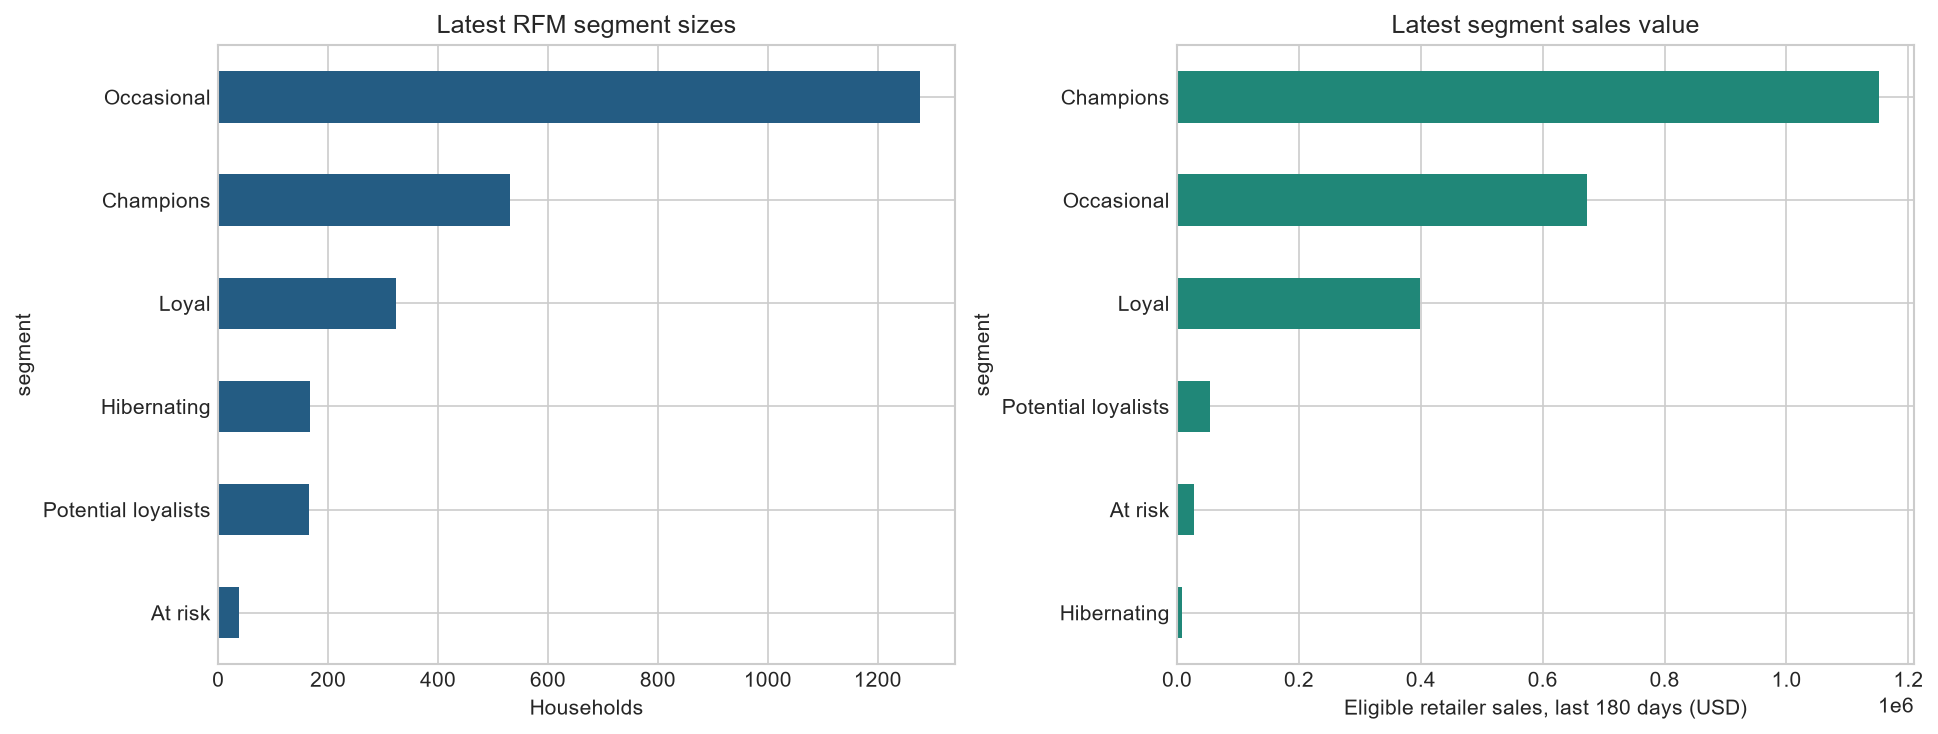

In [8]:
axes[1].set(
    xlabel="Eligible retailer sales, last 180 days (USD)",
    title="Latest segment sales value",
)
finish(fig, "04_rfm_segments.png")


## Interpretation and handoff

Segment rules are initial analyst definitions. They help explain an audience, but do not prove whether a discount changes behaviour. The existing risk model uses purchase-history features rather than RFM labels, and the scenario selector does not optimise segment membership. Next in the main reading order: notebook 05, then notebook 06. Specific household-coupon pairing is still open work.

In [9]:
con.close()
